In [24]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/8/2022
# version ='1.0'

### Demo: Newton's method on the log-barrier function in $R^{100}$ 

In the text book {book-convex-2004}, section 9.5, 'Newton's method', the following minimization problem in $R^{100}$ was discussed. In this demo, an experiment is implemented in python to further visualize the quadratic convergence of Newton's method between backtracking line search and exact line search, and the effect from the parameters ($\alpha, \beta$) on the performance of the Newton's method. 

$$
\min f(x) = c^T x - \displaystyle{\sum_{i=1}^{m}\log(b_i-a_i^Tx)}
$$

where, $m=500, n=100$. The gradient and the hessian of $f(x)$ is
$$
\begin{array}{rcl}
\nabla f(x)&  = & c + A^T (1/(b-Ax)) \\
\nabla^2 f(x) & = & A^T diag(1/(b-Ax)^2) A \\
\end{array}
$$


In the exact line search in the experiment, unfortunately, the solution for 
$$t=arg\displaystyle{\min_{s\geq 0}f(x+s\Delta x)}
$$
does not have an analytical form, so the numerical computation using scipy.optimize.minimize is used, with bounds that 
$$
0 < s < s_{upper}=\displaystyle{\max_{s>0}\{s|x+s\Delta x \in \mathcal{D}_f\}}
$$
In scipy.optimize.minimize, the 'Powell' method is simulated with a numerical tolerance of 1e-12.

The first experiment result is comparing the backtracking line search to the exact line search in the Newton's method.

The second experiment result is showing the number of newton iterations for different $\alpha$, $\beta$ in the backtracking line search..


More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb).

In [25]:
import numpy as np
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from scipy.optimize import minimize
from numpy import linalg as LA
from matplotlib import patches


$f(x)=c^T x - \displaystyle{\sum_{i=1}^{m}\log(b_i-a_i^Tx)}$

The gradient of $f(x)$, $\nabla f(x) = c + A^T (1/(b-Ax))$

The hessian of $f(x)$, $\nabla^2 f(x) = A^T diag(1/(b-Ax)^2) A$

The feasibility of x: $b-Ax \succeq 0$

In [26]:
def my_f_fesasible(x, c, b, A):
    """
    The feasibility of x: $b-Ax \succeq 0$
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    return np.all(b - A @ x > 0)


def my_f(x, c, b, A):
    """
    $f(x)=c^T x - \displaystyle{\sum_{i=1}^{m}\log(b_i-a_i^Tx)}$
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    return (c.T @ x - np.sum(np.log(b - A @ x))).item()


def my_gradient_f(x, c, b, A):
    """
    The gradient of $f(x)$, $\nabla f(x) = c + A^T (1/(b-Ax))$
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    return c + np.sum(A.T @ (1 / (b - A @ x)), axis=1).reshape((-1, 1))


def my_hessian_f(x, c, b, A):
    """
    The hessian of $f(x)$, $\nabla^2 f(x) = A^T diag(1/(b-Ax)^2) A$
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    n = len(x)
    m = len(b)
    diag = np.diag(np.squeeze(1 / ((b - A @ x) ** 2)))
    hessian = A.T @ diag @ A
    return hessian

In [27]:
def my_newton_step_decrement(x, c, b, A):
    """
    calculate the newton decrement
    :param x:
    :param c:
    :param b:
    :param A:
    :return:
    """
    gradient = my_gradient_f(x, c, b, A)
    hessian = my_hessian_f(x, c, b, A)
    hessian_inv = np.linalg.inv(hessian)
    x_nt = -1 * hessian_inv @ gradient
    decrement = -1 * gradient.T @ x_nt
    return x_nt, decrement.item()

In [28]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    backtracking line search
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    t = 1
    while (not my_f_fesasible(x + delta_x * t, *args)) \
            or f(x + delta_x * t, *args) > f(x, *args) + alpha * t * ((df(x, *args).T @ delta_x).item()):
        t = beta * t
    return t

get the upper bound of $t$, satisfying $b-A(x+t\Delta x) \succeq 0$

In [29]:
def get_upper_bound_t(x, dx, c, b, A):
    """
    get the upper bound of $t$, satisfying $b-A(x+t\Delta x) \succeq 0$
    :param x:
    :param dx:
    :param c:
    :param b:
    :param A:
    :return:
    """
    y = b - A @ x
    z = A @ dx
    t_bounds = np.array([np.inf if z[i] <= 0 else y[i][0] / z[i][0] for i in range(len(z))])
    t_upper_bound = np.amin(t_bounds)
    if t_upper_bound == 0:
        raise RuntimeError("get_upper_bound_t error")
    return t_upper_bound

Numerical computation using scipy.optimize.minimize is used to solve the exact line search problem.

In scipy.optimize.minimize, the 'Powell' method is simulated with a numerical tolerance of 1e-12.

In [30]:
def exact_line_search(f, x, dx, method, args):
    """
    Numerical computation using scipy.optimize.minimize is used to solve the exact line search problem.
    In scipy.optimize.minimize, the 'Powell' method is simulated with a numerical tolerance of 1e-12.
    :param f:
    :param x:
    :param dx:
    :param method:
    :param args:
    :return:
    """
    def exact_line_search_min_f(s, f, x, dx, args):
        return f(x + s * dx, *args)

    s_upper_bound = get_upper_bound_t(x, dx, *args)
    s0 = s_upper_bound * 0.5
    epsilon = 1e-12
    gamma = 0.8
    while True:
        res = minimize(exact_line_search_min_f, s0, args=(f, x, dx, args), bounds=[(0, s_upper_bound)], method=method)
        if res.success:
            if f(x + res.x * dx, *args) - f(x, *args) < 0 or np.abs(f(x, *args) - f(x + res.x * dx, *args)) < epsilon:
                break
            else:
                s0 = res.x * gamma
        else:
            s0 = s0 * gamma
    return res.x

Plot the convergence of the newton method applied to the log barrier function, using either backtracking line search or exact line search

In [31]:
def plot_convergence_newton_method_log_barrier(ax1, ax2):
    """
    plot the convergence of the newton method applied to the log barrier function, using either backtracking line search or exact line search.
    :param ax1:
    :param ax2:
    :return:
    """
    np.random.seed(1)
    m = 500
    n = 100
    A = np.random.rand(m, n)

    if not np.linalg.matrix_rank(A) == n:
        raise RuntimeError("rank(A) should be equal to n!")

    Lambda = -1 * np.random.rand(m, 1)
    c = A.T @ Lambda
    inv_Lambda = 1 / Lambda
    b = -1 * inv_Lambda
    f_min = -np.sum(np.log(b)).item()

    args = (c, b, A)

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-10

    # backtracking line search
    x0 = -1 * np.ones([n, 1])
    x = x0
    x_nt, decrement = my_newton_step_decrement(x, c, b, A)
    fx = [my_f(x, *args)]
    tx = []
    iteration = 0
    while decrement / 2 > epsilon:
        print('Info: decrement = {}, fx={}'.format(decrement, fx[-1]))
        t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        tx.append(t)
        x_next = x + t * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, c, b, A)

        fx.append(my_f(x, *args))
        iteration = iteration + 1

    ax = plt.subplot(1, 2, 1)
    ax.semilogy(np.array(fx) - f_min, marker='x', label=r"backtracking line")

    ax = plt.subplot(1, 2, 2)
    ax.plot(np.arange(1, len(tx) + 1), tx, marker='+', label=r"backtracking line")

    x0 = -1 * np.ones([n, 1])
    x = x0
    x_nt, decrement = my_newton_step_decrement(x, c, b, A)
    fx = [my_f(x, *args)]
    tx = []
    iteration = 0
    while decrement / 2 > epsilon:
        print('Info: decrement = {}, fx={}'.format(decrement, fx[-1]))
        method = 'Powell'
        t = exact_line_search(my_f, x, x_nt, method, args)
        tx.append(t)
        x_next = x + t * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, c, b, A)
        fx.append(my_f(x, *args))
        iteration = iteration + 1

    ax1.semilogy(np.array(fx) - f_min, marker='x', label=r"exact line (Powell)")
    ax1.grid()
    ax1.legend()
    ax1.set_xlabel('iteration')
    ax1.set_title(r'$f(x)-p^*$')

    ax2.plot(np.arange(1, len(tx) + 1), tx, marker='+', label=r"exact line (Powell)")
    ax2.grid()
    ax2.legend()
    ax2.set_xlabel('iteration')
    ax2.set_title(r't in each step of line search')

In [32]:
def plot_newton_method_convergence_different_alpha_beta(m, n, alphas, betas):
    np.random.seed(1)

    A = np.random.rand(m, n)

    if not np.linalg.matrix_rank(A) == n:
        raise RuntimeError("rank(A) should be equal to n!")

    Lambda = -1 * np.random.rand(m, 1)
    c = A.T @ Lambda
    inv_Lambda = 1 / Lambda
    b = -1 * inv_Lambda
    f_min = -np.sum(np.log(b)).item()

    args = (c, b, A)
    epsilon = 1e-10
    for alpha in alphas:
        print('Info: alpha={}'.format(alpha))

        num_iters = []

        for beta in betas:
            print('Info: beta={}'.format(beta))
            # backtracking line search
            x0 = -1 * np.ones([n, 1])
            x = x0
            x_nt, decrement = my_newton_step_decrement(x, c, b, A)
            fx = []
            tx = []
            fx.append(my_f(x, *args))
            iter = 0
            while decrement / 2 > epsilon:
                #print('decrement = {}, fx={}'.format(decrement, fx[-1]))
                t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
                tx.append(t)
                x_next = x + t * x_nt
                x = x_next
                x_nt, decrement = my_newton_step_decrement(x, c, b, A)

                fx.append(my_f(x, *args))
                iter = iter + 1

            num_iters.append(iter)

        ax = plt.subplot(1, 1, 1)
        ax.plot(betas, num_iters, marker='+', fillstyle='none', linestyle='dashed', label=r"$\alpha={:.4f}$".format(alpha))

    ax.yaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.grid()
    ax.legend()
    ax.set_xlabel(r'$\beta$')
    ax.set_title(r'num. of iterations')

In [33]:
def plot_convergence():
    plt.figure(figsize=(12, 4))
    ax1 = plt.subplot(1, 2, 1)
    ax2 = plt.subplot(1, 2, 2)
    plot_convergence_newton_method_log_barrier(ax1, ax2)
    plt.show()

In [34]:
def plot_convergences():
    plt.figure(figsize=(12, 4))
    m = 50
    n = 10
    num_beta = 8
    num_alpha_1 = 2
    num_alpha_2 = 5
    num_alpha_3 = 5
    alphas = np.concatenate([np.linspace(0.005, 0.45 - (0.45-0.005)/num_alpha_1, num=num_alpha_1),
                             np.linspace(0.45, 0.49 - (0.49-0.45)/num_alpha_2, num=num_alpha_2),
                             np.linspace(0.49, 0.5, num=num_alpha_3)])
    betas = np.linspace(0.2, 0.9, num=num_beta)
    plot_newton_method_convergence_different_alpha_beta(m=m, n=n, alphas=alphas, betas=betas)
    plt.show()

Info: decrement = 362323.44212318596, fx=10708.415081997518
Info: decrement = 103531.35070689616, fx=5112.829186776474
Info: decrement = 26278.612109819627, fx=1952.5140885196042
Info: decrement = 5594.656629935972, fx=387.0581214364322
Info: decrement = 994.3657503259442, fx=-248.428895882471
Info: decrement = 121.85473579180382, fx=-454.11347692075196
Info: decrement = 42.36951979461891, fx=-468.69662480361245
Info: decrement = 7.113290958291637, fx=-494.326516635465
Info: decrement = 0.2058883928122684, fx=-498.2332412562066
Info: decrement = 0.000252259876912867, fx=-498.3383970539071
Info: decrement = 7.480699915281414e-10, fx=-498.3385233201702
Info: decrement = 362323.44212318596, fx=10708.415081997518
Info: decrement = 45059.779348096345, fx=2882.272251583853
Info: decrement = 932.9529471832429, fx=-272.02747838423943
Info: decrement = 19.843308234851897, fx=-485.00132897901585
Info: decrement = 2.5805026109135794, fx=-494.1272857669663
Info: decrement = 1.9581945580712197, fx=

C:\Users\Edwin\AppData\Local\Temp/ipykernel_28592/481232026.py:22: RuntimeWarning: invalid value encountered in log
  return (c.T @ x - np.sum(np.log(b - A @ x))).item()


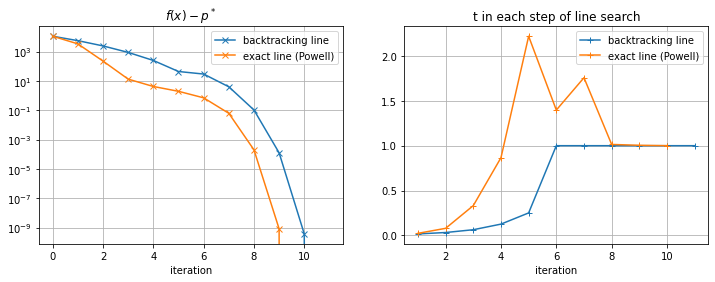

In [35]:
if __name__ == "__main__":
    plot_convergence()

Info: alpha=0.005
Info: beta=0.2
Info: beta=0.3
Info: beta=0.4
Info: beta=0.5
Info: beta=0.6
Info: beta=0.7
Info: beta=0.8
Info: beta=0.9
Info: alpha=0.2275
Info: beta=0.2
Info: beta=0.3
Info: beta=0.4
Info: beta=0.5
Info: beta=0.6
Info: beta=0.7
Info: beta=0.8
Info: beta=0.9
Info: alpha=0.45
Info: beta=0.2
Info: beta=0.3
Info: beta=0.4
Info: beta=0.5
Info: beta=0.6
Info: beta=0.7
Info: beta=0.8
Info: beta=0.9
Info: alpha=0.458
Info: beta=0.2
Info: beta=0.3
Info: beta=0.4
Info: beta=0.5
Info: beta=0.6
Info: beta=0.7
Info: beta=0.8
Info: beta=0.9
Info: alpha=0.46599999999999997
Info: beta=0.2
Info: beta=0.3
Info: beta=0.4
Info: beta=0.5
Info: beta=0.6
Info: beta=0.7
Info: beta=0.8
Info: beta=0.9
Info: alpha=0.474
Info: beta=0.2
Info: beta=0.3
Info: beta=0.4
Info: beta=0.5
Info: beta=0.6
Info: beta=0.7
Info: beta=0.8
Info: beta=0.9
Info: alpha=0.482
Info: beta=0.2
Info: beta=0.3
Info: beta=0.4
Info: beta=0.5
Info: beta=0.6
Info: beta=0.7
Info: beta=0.8
Info: beta=0.9
Info: alpha=0.49
Inf

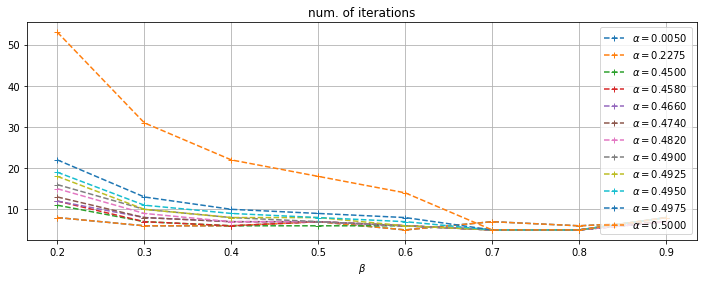

In [36]:
if __name__ == "__main__":
    plot_convergences()